# NB10 — Classical ML baselines + homophily audit (GeoGraphNet, EuroSAT-MS)
**Inputs (Datasets only):** `eurosat-geograph-nb1-v2` (X16, labels, folds) and `eurosat-geograph-nb3-v2` (`graphs_K25_m20.npz`). CPU is enough (no GPU).
**Part A:** Random Forest and RBF-SVM on hand-crafted band statistics, same 5-fold protocol (fold k = test, (k+1)%5 = validation, other three = training) and the same metrics as the deep models.
**Part B:** homophily audit of the superpixel graph: how similar (Spectral Angle Mapper) are the two end-points of spatial edges, spectral k-NN edges, and random region pairs?

In [2]:
# Cell 1: load
import os, glob, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import f1_score, cohen_kappa_score
ROOT = os.environ.get("NB10_ROOT", "/kaggle/input"); OUT = os.environ.get("NB10_OUT", "/kaggle/working")
QUICK = bool(int(os.environ.get("NB10_QUICK", "0")))
def find_one(name):
    hits = glob.glob(ROOT + "/**/" + name, recursive=True)
    assert len(hits) == 1, (name, hits)
    return hits[0]
X16 = np.load(find_one("X16_float16.npy"), mmap_mode="r")
labels = np.load(find_one("labels.npy")).astype(np.int64)
fd = pd.read_csv(find_one("folds.csv")); fold = fd[[c for c in fd.columns if "fold" in c.lower()][0]].values
N = len(labels); assert X16.shape[0] == N == len(fold)
print(X16.shape, np.bincount(fold))

(27000, 16, 64, 64) [5400 5400 5400 5400 5400]


In [4]:
 #Cell 2 (Part A): hand-crafted features = per-channel mean and std of the 16 channels (32 values per patch)
feat = np.zeros((N, 32), np.float32)
for i in range(0, N, 1000):
    xb = np.asarray(X16[i:i + 1000], np.float32).reshape(-1, 16, 4096)
    feat[i:i + 1000, :16] = xb.mean(2); feat[i:i + 1000, 16:] = xb.std(2)
print(feat.shape, "finite:", np.isfinite(feat).all())

(27000, 32) finite: True


In [5]:
# Cell 3 (Part A): 5-fold CV for Random Forest and SVM
def ece(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1); acc = (pred == y).astype(float); e = 0.0; edges = np.linspace(0, 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any(): e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e
folds = [0] if QUICK else [0, 1, 2, 3, 4]
rows = []; probs = {}
for k in folds:
    te = np.where(fold == k)[0]; va = np.where(fold == (k + 1) % 5)[0]; tr = np.where(~np.isin(fold, [k, (k + 1) % 5]))[0]
    for name in ["RandomForest", "SVM_RBF"]:
        t0 = time.time()
        if name == "RandomForest":
            clf = RandomForestClassifier(n_estimators=100 if QUICK else 500, n_jobs=-1, random_state=42).fit(feat[tr], labels[tr])
        else:
            clf = make_pipeline(StandardScaler(), SVC(C=10, kernel="rbf", gamma="scale", random_state=42)).fit(feat[tr], labels[tr])
        pred = clf.predict(feat[te]); yt = labels[te]
        r = dict(Exp=name, Fold=k, Acc=100 * (pred == yt).mean(), Macro_F1=100 * f1_score(yt, pred, average="macro"), Kappa=cohen_kappa_score(yt, pred), Train_Min=(time.time() - t0) / 60)
        if name == "RandomForest":
            p = clf.predict_proba(feat[te]); r["ECE"] = ece(p, yt); probs[f"test_{name}_f{k}"] = p.astype(np.float32)
        rows.append(r); print({a: (round(b, 3) if isinstance(b, float) else b) for a, b in r.items()})
cl = pd.DataFrame(rows); cl.round(4).to_csv(f"{OUT}/nb10_classical_cv.csv", index=False)
np.savez_compressed(f"{OUT}/nb10_classical_probs.npz", **probs)
print(cl.groupby("Exp")[["Acc", "Macro_F1", "Kappa"]].agg(["mean", "std"]).round(3))
print("Reference deep models (5-fold Macro-F1): B1 98.41, B2 98.16, B3 98.76, A3 98.73, A4 98.81, A5 98.72")

{'Exp': 'RandomForest', 'Fold': 0, 'Acc': np.float64(90.463), 'Macro_F1': 89.979, 'Kappa': np.float64(0.894), 'Train_Min': 0.397, 'ECE': np.float64(0.092)}
{'Exp': 'SVM_RBF', 'Fold': 0, 'Acc': np.float64(93.278), 'Macro_F1': 92.869, 'Kappa': np.float64(0.925), 'Train_Min': 0.06}
{'Exp': 'RandomForest', 'Fold': 1, 'Acc': np.float64(89.907), 'Macro_F1': 89.482, 'Kappa': np.float64(0.888), 'Train_Min': 0.394, 'ECE': np.float64(0.092)}
{'Exp': 'SVM_RBF', 'Fold': 1, 'Acc': np.float64(94.019), 'Macro_F1': 93.769, 'Kappa': np.float64(0.933), 'Train_Min': 0.059}
{'Exp': 'RandomForest', 'Fold': 2, 'Acc': np.float64(90.815), 'Macro_F1': 90.319, 'Kappa': np.float64(0.898), 'Train_Min': 0.395, 'ECE': np.float64(0.094)}
{'Exp': 'SVM_RBF', 'Fold': 2, 'Acc': np.float64(93.611), 'Macro_F1': 93.204, 'Kappa': np.float64(0.929), 'Train_Min': 0.058}
{'Exp': 'RandomForest', 'Fold': 3, 'Acc': np.float64(90.222), 'Macro_F1': 89.793, 'Kappa': np.float64(0.891), 'Train_Min': 0.393, 'ECE': np.float64(0.092)}
{'

In [6]:
# Cell 4 (Part B): homophily audit of the cached graphs (K=25, m=20)
G = dict(np.load(find_one("graphs_K25_m20.npz")))
print({k: v.shape for k, v in G.items()})
n_per = np.diff(G["node_ptr"]); e_per = np.diff(G["edge_ptr"]); ea = G["edge_attr"]; et = G["edge_type"]
pid = np.repeat(np.arange(len(e_per)), e_per)                       # patch id of every edge
sam, dist = ea[:, 1], ea[:, 0]                                       # edge attributes: [centroid distance, SAM, shared-boundary ratio]
# baseline: SAM between ALL region pairs inside a patch (sample of patches)
rng = np.random.default_rng(0); samp = rng.choice(len(n_per), min(2000, len(n_per)), replace=False); allsam = []
for i in samp:
    a, b = int(G["node_ptr"][i]), int(G["node_ptr"][i + 1]); u = G["node_static"][a:b, :13].astype(np.float64)
    u = u / (np.linalg.norm(u, axis=1, keepdims=True) + 1e-6); S = np.arccos(np.clip(u @ u.T, -1, 1)); allsam.append(S[np.triu_indices(len(u), 1)])
allsam = np.concatenate(allsam); tau = float(np.median(allsam))
sp, sc = sam[et == 0], sam[et == 1]
tab = pd.DataFrame({"set": ["spatial edges", "spectral k-NN edges", "all region pairs (baseline)"],
                    "n": [len(sp), len(sc), len(allsam)], "mean_SAM_rad": [sp.mean(), sc.mean(), allsam.mean()], "median_SAM_rad": [np.median(sp), np.median(sc), np.median(allsam)],
                    "edge_homophily_at_tau": [(sp < tau).mean(), (sc < tau).mean(), (allsam < tau).mean()],
                    "mean_centroid_dist": [dist[et == 0].mean(), dist[et == 1].mean(), np.nan]}).round(4)
print("tau (median SAM of all pairs) = %.4f rad" % tau); print(tab.to_string(index=False)); tab.to_csv(f"{OUT}/nb10_homophily.csv", index=False)
print("edges per patch: spatial %.1f | spectral %.1f | regions per patch %.1f" % ((et == 0).sum() / len(n_per), (et == 1).sum() / len(n_per), n_per.mean()))

{'seg': (27000, 64, 64), 'n_nodes': (27000,), 'node_ptr': (27001,), 'node_static': (599733, 36), 'edge_ptr': (27001,), 'edge_index': (2, 4361363), 'edge_attr': (4361363, 3), 'edge_type': (4361363,)}
tau (median SAM of all pairs) = 0.0611 rad
                        set       n  mean_SAM_rad  median_SAM_rad  edge_homophily_at_tau  mean_centroid_dist
              spatial edges 2562178        0.0920          0.0528                 0.5519              0.2380
        spectral k-NN edges 1799185        0.0425          0.0275                 0.8161              0.5756
all region pairs (baseline)  479265        0.1105          0.0611                 0.5000                 NaN
edges per patch: spatial 94.9 | spectral 66.6 | regions per patch 22.2


               class  mean_SAM_spatial  mean_SAM_spectral  ratio_spectral_over_spatial
          AnnualCrop            0.1047             0.0464                        0.443
              Forest            0.0399             0.0209                        0.524
HerbaceousVegetation            0.0590             0.0307                        0.520
             Highway            0.1211             0.0599                        0.495
          Industrial            0.1281             0.0689                        0.538
             Pasture            0.0751             0.0364                        0.485
       PermanentCrop            0.0773             0.0359                        0.464
         Residential            0.0803             0.0408                        0.508
               River            0.2348             0.0847                        0.361
             SeaLake            0.0345             0.0211                        0.612


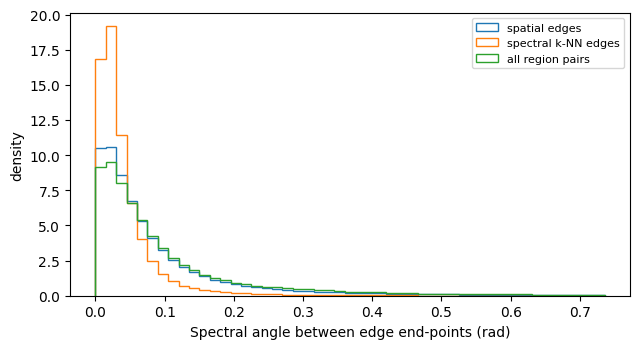

['.virtual_documents', 'nb10_classical_cv.csv', 'nb10_classical_probs.npz', 'nb10_homophily.csv', 'nb10_homophily.png', 'nb10_homophily_by_class.csv']


In [7]:
# Cell 5 (Part B): per-class view and figure
CLS = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial", "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
cls_e = labels[pid]
pc = pd.DataFrame({"class": CLS, "mean_SAM_spatial": [sam[(et == 0) & (cls_e == c)].mean() for c in range(10)],
                   "mean_SAM_spectral": [sam[(et == 1) & (cls_e == c)].mean() for c in range(10)]}).round(4)
pc["ratio_spectral_over_spatial"] = (pc.mean_SAM_spectral / pc.mean_SAM_spatial).round(3); print(pc.to_string(index=False)); pc.to_csv(f"{OUT}/nb10_homophily_by_class.csv", index=False)
plt.figure(figsize=(6.5, 3.6)); bins = np.linspace(0, max(np.percentile(allsam, 99), np.percentile(sp, 99)), 50)
for d, lab in [(sp, "spatial edges"), (sc, "spectral k-NN edges"), (allsam, "all region pairs")]: plt.hist(d, bins=bins, histtype="step", density=True, label=lab, lw=1.4)
plt.xlabel("Spectral angle between edge end-points (rad)"); plt.ylabel("density"); plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{OUT}/nb10_homophily.png", dpi=150); plt.show()
print(sorted(os.listdir(OUT)))